In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Pothole.v1-raw.yolov8.zip"
extract_path = "/content/pothole_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")

Dataset extracted!


In [ ]:
print(os.listdir("/content/pothole_dataset"))

['README.roboflow.txt', 'test', 'valid', 'README.dataset.txt', 'train', 'data.yaml']


In [ ]:
print("Train:", len(os.listdir("/content/pothole_dataset/train/images")))
print("Valid:", len(os.listdir("/content/pothole_dataset/valid/images")))
print("Test:", len(os.listdir("/content/pothole_dataset/test/images")))

Train: 465
Valid: 133
Test: 67


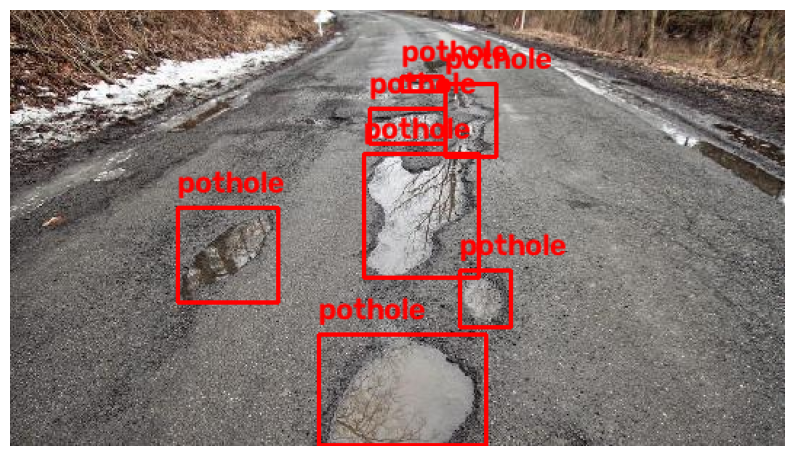

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

image_dir = "/content/pothole_dataset/train/images"
label_dir = "/content/pothole_dataset/train/labels"

# Get one image
image_name = os.listdir(image_dir)[0]

image_path = os.path.join(image_dir, image_name)

# Corresponding label file
label_name = os.path.splitext(image_name)[0] + ".txt"
label_path = os.path.join(label_dir, label_name)

# Read image
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Image dimensions
height, width, _ = image.shape

# Read YOLO labels
with open(label_path, "r") as f:
    labels = f.readlines()

# Draw bounding boxes
for label in labels:

    class_id, center_x, center_y, box_width, box_height = map(
        float, label.split()
    )

    # Convert normalized coordinates → pixel coordinates
    center_x *= width
    center_y *= height
    box_width *= width
    box_height *= height

    # Calculate corners
    x1 = int(center_x - box_width / 2)
    y1 = int(center_y - box_height / 2)
    x2 = int(center_x + box_width / 2)
    y2 = int(center_y + box_height / 2)

    # Draw bounding box
    cv2.rectangle(
        image,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        2
    )

    # Class name
    cv2.putText(
        image,
        "pothole",
        (x1, y1 - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(10, 7))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 10.9 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

In [ ]:
results = model.train(
    data="/content/pothole_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pothole_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False,

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train-2/weights/best.pt")

print("Best model loaded!")

Best model loaded!


In [ ]:
results = model.predict(
    source="/content/pothole_dataset/test/images",
    conf=0.5,
    save=True
)


image 1/67 /content/pothole_dataset/test/images/img-105_jpg.rf.3fe9dff3d1631e79ecb480ff403bcb86.jpg: 640x640 2 potholes, 7.2ms
image 2/67 /content/pothole_dataset/test/images/img-107_jpg.rf.2e40485785f6e5e2efec404301b235c2.jpg: 640x640 2 potholes, 7.2ms
image 3/67 /content/pothole_dataset/test/images/img-146_jpg.rf.61be25b3053a51f622a244980545df2b.jpg: 640x640 1 pothole, 11.7ms
image 4/67 /content/pothole_dataset/test/images/img-161_jpg.rf.211541e7178a4a93ec0680f26b905427.jpg: 640x640 2 potholes, 11.9ms
image 5/67 /content/pothole_dataset/test/images/img-168_jpg.rf.af3590e07b06b43e91fa53990ff94af3.jpg: 640x640 2 potholes, 10.8ms
image 6/67 /content/pothole_dataset/test/images/img-179_jpg.rf.8632eb0d9b75fefe144829e67b75015a.jpg: 640x640 5 potholes, 11.2ms
image 7/67 /content/pothole_dataset/test/images/img-195_jpg.rf.f77a8f4d432a9a89235168ff8e09a650.jpg: 640x640 3 potholes, 10.9ms
image 8/67 /content/pothole_dataset/test/images/img-196_jpg.rf.c1e105382a0bb8d329959cea45173cdf.jpg: 640x6

Number of predicted images: 67


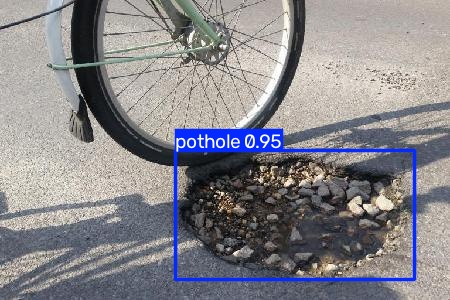

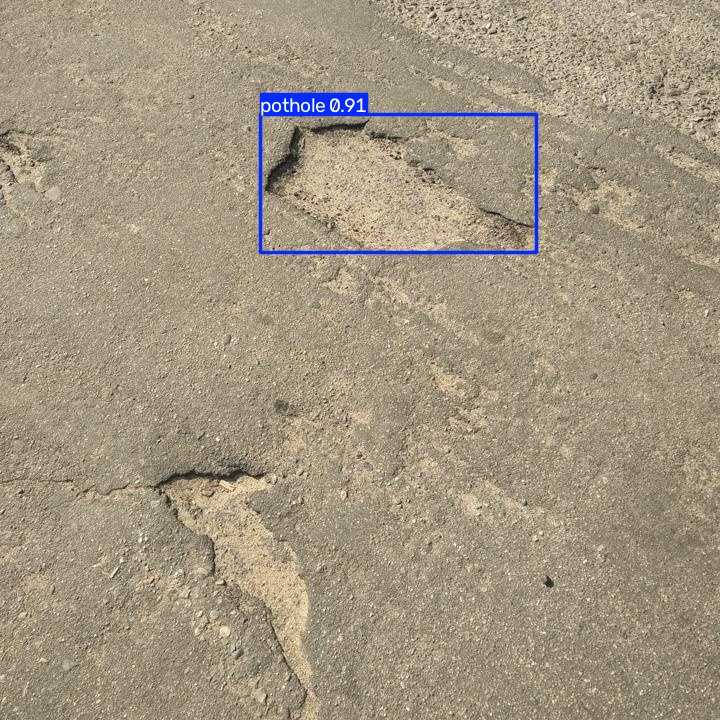

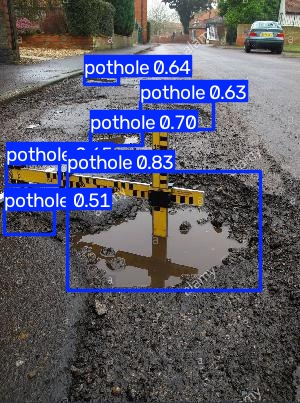

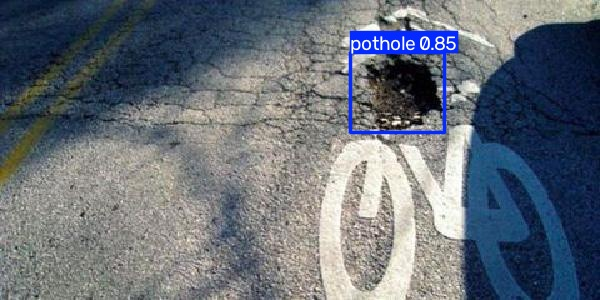

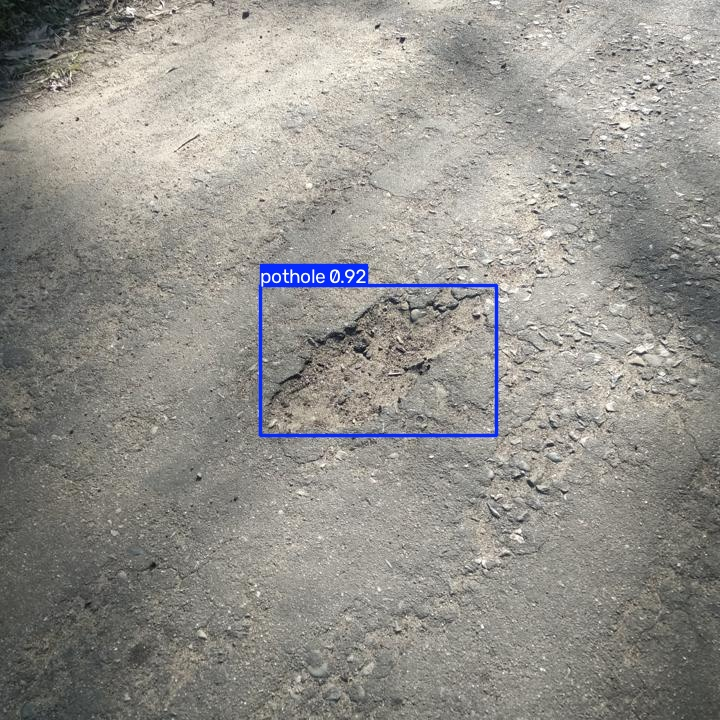

In [ ]:
import glob
from IPython.display import Image, display

# Find the latest prediction folder
prediction_images = glob.glob("/content/runs/detect/predict/*.jpg")

print("Number of predicted images:", len(prediction_images))

# Display first 5 predictions
for img_path in prediction_images[:5]:
    display(Image(filename=img_path, width=800))

In [ ]:
test_results = model.val(
    data="/content/pothole_dataset/data.yaml",
    split="test",
    imgsz=640,
    device=0
)

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1662.9±861.9 MB/s, size: 69.8 KB)
val: Scanning /content/pothole_dataset/test/labels... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 1.7Kit/s 0.0s
val: New cache created: /content/pothole_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.4it/s 3.5s
                   all         67        154      0.774      0.727      0.779      0.504
Speed: 5.9ms preprocess, 15.6ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /content/runs/detect/val


In [ ]:
from google.colab import files

model_path = "/content/runs/detect/train-2/weights/best.pt"

files.download(model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving p3.jpg to p3.jpg
Image uploaded: p3.jpg

image 1/1 /content/p3.jpg: 640x480 9 potholes, 5.8ms
Speed: 2.3ms preprocess, 5.8ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict-5


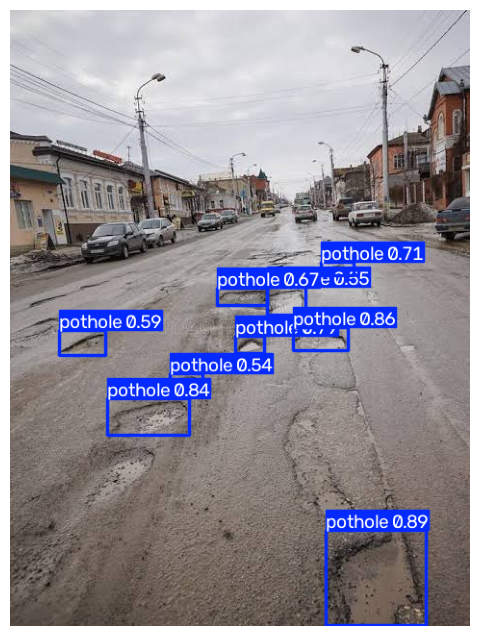


========== DETECTION RESULTS ==========
Pothole 1: Confidence = 0.89
Pothole 2: Confidence = 0.86
Pothole 3: Confidence = 0.84
Pothole 4: Confidence = 0.79
Pothole 5: Confidence = 0.71
Pothole 6: Confidence = 0.67
Pothole 7: Confidence = 0.59
Pothole 8: Confidence = 0.55
Pothole 9: Confidence = 0.54


In [ ]:
# ============================================
# Pothole Detection - Upload & Predict
# ============================================

from google.colab import files
from ultralytics import YOLO
import matplotlib.pyplot as plt

# 1. Load your trained model
model_path = "/content/runs/detect/train-2/weights/best.pt"
model = YOLO(model_path)

# 2. Upload an image from your PC
uploaded = files.upload()

# Get uploaded image name
image_name = list(uploaded.keys())[0]

print(f"Image uploaded: {image_name}")

# 3. Run pothole detection
results = model.predict(
    source=image_name,
    conf=0.5,
    save=True
)

# 4. Get the first result
result = results[0]

# 5. Display image with bounding boxes
annotated_image = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.show()

# 6. Print detected potholes
boxes = result.boxes

print("\n========== DETECTION RESULTS ==========")

if boxes is not None and len(boxes) > 0:

    for i, box in enumerate(boxes):
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        print(
            f"Pothole {i + 1}: "
            f"Confidence = {confidence:.2f}"
        )

else:
    print("No potholes detected.")

print("=======================================")